# Olist 数据质量检测（PySpark 直接读 HDFS 版）

本 Notebook 使用 **PySpark 直接读取 HDFS 上的 CSV 文件**，对 Olist 9 张表做系统质量检测，每个检测模块后**立即可视化**。

> **为什么不用 Hive 表？** 你的环境是 Hive 2.1.1 + Spark 3.4.1，Metastore 未配置 thrift uris，Spark 无法直接连 Hive 表。改用 Spark 直接读 HDFS 原始 CSV，绕开 Metastore 兼容问题，功能完全一致。

**前置条件**：
1. 数据已在 HDFS `/olist/data/` 目录（9 个 CSV）
2. Hadoop 已启动（NameNode/DataNode）
3. 已安装：`pip install pyspark pandas matplotlib`

**中文字体**：使用 `Olist/fonts/SimHei.ttf`。

**运行方式**（在虚拟机上）：
```bash
cd ~/Olist
jupyter notebook
```

## 0. 环境配置：初始化 SparkSession（不连 Hive）+ 中文字体

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# ===== 中文字体（使用虚拟机的 SimHei.ttf）=====
FONT_PATH = os.path.expanduser("~/Olist/fonts/SimHei.ttf")
if os.path.exists(FONT_PATH):
    fm.fontManager.addfont(FONT_PATH)
    font_name = fm.FontProperties(fname=FONT_PATH).get_name()
    plt.rcParams['font.sans-serif'] = [font_name]
    print(f"[OK] 已加载中文字体: {font_name}")
else:
    plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
    print(f"[WARN] 未找到 {FONT_PATH}，中文可能乱码")
plt.rcParams['axes.unicode_minus'] = False


[OK] 已加载中文字体: SimHei


In [2]:
from pyspark.sql import SparkSession

# ===== 初始化 SparkSession（不启用 Hive 支持）=====
# 说明：这里用纯 Spark，直接读 HDFS 上的 CSV，不依赖 Hive Metastore
spark = (
    SparkSession.builder
    .appName("Olist-DataQuality")
    .master("local[*]")          # 本地模式，用满 CPU 核
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

print("[OK] SparkSession 已创建，Spark 版本:", spark.version)


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/22 17:03:34 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


[OK] SparkSession 已创建，Spark 版本: 3.4.1


In [3]:
# ===== 定义 HDFS 数据路径和表结构 =====
HDFS_DATA = "hdfs://node100:9000/olist/data"

# 每个文件的 schema（列名 + 类型），用 STRING 先读入再按需 cast
from pyspark.sql.types import StructType, StructField, StringType

def read_csv(filename, schema_fields):
    """读 HDFS 上的 CSV，返回 DataFrame（跳过表头，自动推断）"""
    path = f"{HDFS_DATA}/{filename}"
    schema = StructType([StructField(f, StringType(), True) for f in schema_fields])
    return (
        spark.read
        .option("header", "true")       # 第一行是表头
        .option("inferSchema", "false") # 先用字符串，避免类型推断错
        .schema(schema)
        .csv(path)
    )

# 注册各表为临时视图，方便后面 spark.sql 查询
def register_all():
    read_csv("olist_customers_dataset.csv",
             ["customer_id","customer_unique_id","customer_zip_code_prefix","customer_city","customer_state"]
    ).createOrReplaceTempView("customers")

    read_csv("olist_geolocation_dataset.csv",
             ["geolocation_zip_code_prefix","geolocation_lat","geolocation_lng","geolocation_city","geolocation_state"]
    ).createOrReplaceTempView("geolocation")

    read_csv("olist_order_items_dataset.csv",
             ["order_id","order_item_id","product_id","seller_id","shipping_limit_date","price","freight_value"]
    ).createOrReplaceTempView("order_items")

    read_csv("olist_order_payments_dataset.csv",
             ["order_id","payment_sequential","payment_type","payment_installments","payment_value"]
    ).createOrReplaceTempView("order_payments")

    read_csv("olist_order_reviews_dataset.csv",
             ["review_id","order_id","review_score","review_comment_title","review_comment_message","review_creation_date","review_answer_timestamp"]
    ).createOrReplaceTempView("order_reviews")

    read_csv("olist_orders_dataset.csv",
             ["order_id","customer_id","order_status","order_purchase_timestamp","order_approved_at","order_delivered_carrier_date","order_delivered_customer_date","order_estimated_delivery_date"]
    ).createOrReplaceTempView("orders")

    read_csv("olist_products_dataset.csv",
             ["product_id","product_category_name","product_name_lenght","product_description_lenght","product_photos_qty","product_weight_g","product_length_cm","product_height_cm","product_width_cm"]
    ).createOrReplaceTempView("products")

    read_csv("olist_sellers_dataset.csv",
             ["seller_id","seller_zip_code_prefix","seller_city","seller_state"]
    ).createOrReplaceTempView("sellers")

    read_csv("product_category_name_translation.csv",
             ["product_category_name","product_category_name_english"]
    ).createOrReplaceTempView("category_translation")

    print("[OK] 9 张表已注册为临时视图")

register_all()


[OK] 9 张表已注册为临时视图


## 1. 各表数据量总览
对照官方数据量验证完整性。

In [4]:
tables = [
    ("customers", "customers"),
    ("geolocation", "geolocation"),
    ("order_items", "order_items"),
    ("order_payments", "order_payments"),
    ("order_reviews", "order_reviews"),
    ("orders", "orders"),
    ("products", "products"),
    ("sellers", "sellers"),
    ("category_translation", "category_translation"),
]

rows = []
for name, view in tables:
    cnt = spark.sql(f"SELECT COUNT(*) AS c FROM {view}").collect()[0]["c"]
    rows.append((name, cnt))

df_cnt = pd.DataFrame(rows, columns=["table_name", "row_cnt"])
df_cnt


,table_name,row_cnt
0,customers,99441
1,geolocation,1000163
2,order_items,112650
3,order_payments,103886
4,order_reviews,104162
5,orders,99441
6,products,32951
7,sellers,3095
8,category_translation,71


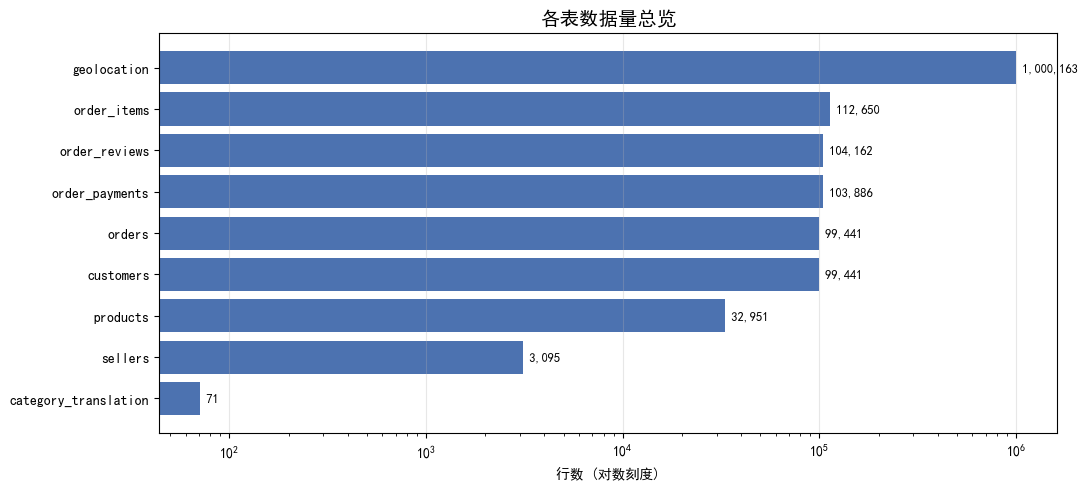

In [5]:
# 可视化：各表数据量柱状图（对数刻度）
fig, ax = plt.subplots(figsize=(11, 5))
df_sorted = df_cnt.sort_values("row_cnt", ascending=True)
bars = ax.barh(df_sorted["table_name"], df_sorted["row_cnt"], color="#4C72B0")
for bar, v in zip(bars, df_sorted["row_cnt"]):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height()/2,
            f" {v:,}", va="center", fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("行数 (对数刻度)")
ax.set_title("各表数据量总览", fontsize=14, fontweight="bold")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


## 2. 关键字段缺失率检测

In [6]:
missing_sql = """
SELECT 'orders.order_approved_at' AS field,
       SUM(CASE WHEN order_approved_at IS NULL OR order_approved_at='' THEN 1 ELSE 0 END) AS missing_cnt,
       COUNT(*) AS total_cnt
FROM orders
UNION ALL
SELECT 'orders.order_delivered_customer_date',
       SUM(CASE WHEN order_delivered_customer_date IS NULL OR order_delivered_customer_date='' THEN 1 ELSE 0 END),
       COUNT(*)
FROM orders
UNION ALL
SELECT 'reviews.review_comment_title',
       SUM(CASE WHEN review_comment_title IS NULL OR review_comment_title='' THEN 1 ELSE 0 END),
       COUNT(*)
FROM order_reviews
UNION ALL
SELECT 'reviews.review_comment_message',
       SUM(CASE WHEN review_comment_message IS NULL OR review_comment_message='' THEN 1 ELSE 0 END),
       COUNT(*)
FROM order_reviews
UNION ALL
SELECT 'products.product_category_name',
       SUM(CASE WHEN product_category_name IS NULL OR product_category_name='' THEN 1 ELSE 0 END),
       COUNT(*)
FROM products
"""
df_missing = spark.sql(missing_sql).toPandas()
df_missing["missing_rate"] = (df_missing["missing_cnt"] / df_missing["total_cnt"] * 100).round(2)
df_missing


,field,missing_cnt,total_cnt,missing_rate
0,orders.order_approved_at,160,99441,0.16
1,orders.order_delivered_customer_date,2965,99441,2.98
2,reviews.review_comment_title,92157,104162,88.47
3,reviews.review_comment_message,63079,104162,60.56
4,products.product_category_name,610,32951,1.85


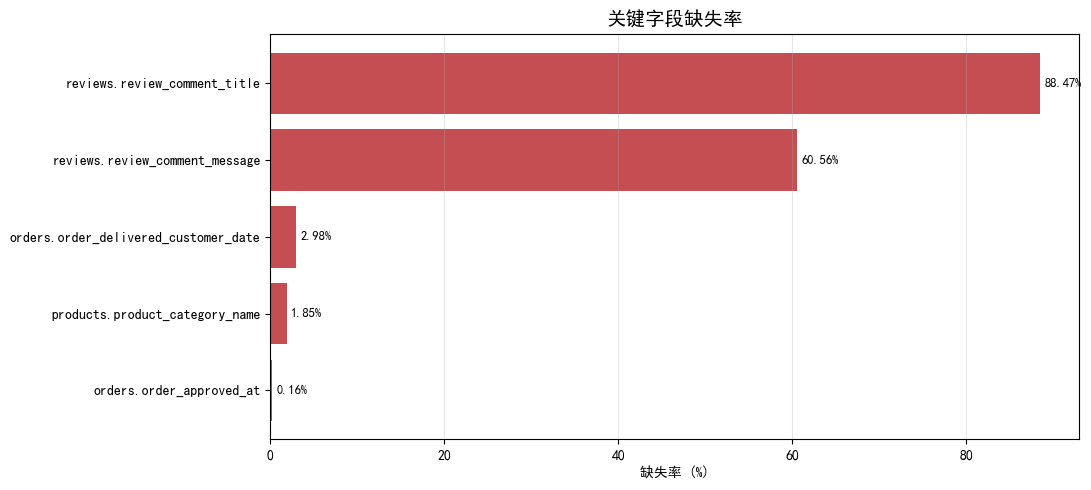

In [7]:
# 可视化：缺失率柱状图
fig, ax = plt.subplots(figsize=(11, 5))
df_m = df_missing.sort_values("missing_rate", ascending=True)
bars = ax.barh(df_m["field"], df_m["missing_rate"], color="#C44E52")
for bar, r in zip(bars, df_m["missing_rate"]):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f"{r}%", va="center", fontsize=9)
ax.set_xlabel("缺失率 (%)")
ax.set_title("关键字段缺失率", fontsize=14, fontweight="bold")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


## 3. 重复值检测（geolocation）

In [8]:
dup_sql = """
SELECT
    COUNT(*) AS total_rows,
    COUNT(DISTINCT geolocation_zip_code_prefix, geolocation_lat,
          geolocation_lng, geolocation_city, geolocation_state) AS distinct_rows
FROM geolocation
"""
df_dup = spark.sql(dup_sql).toPandas()
df_dup["dup_rows"] = df_dup["total_rows"] - df_dup["distinct_rows"]
df_dup["dup_rate"] = (df_dup["dup_rows"] / df_dup["total_rows"] * 100).round(2)
df_dup


,total_rows,distinct_rows,dup_rows,dup_rate
0,1000163,738332,261831,26.18


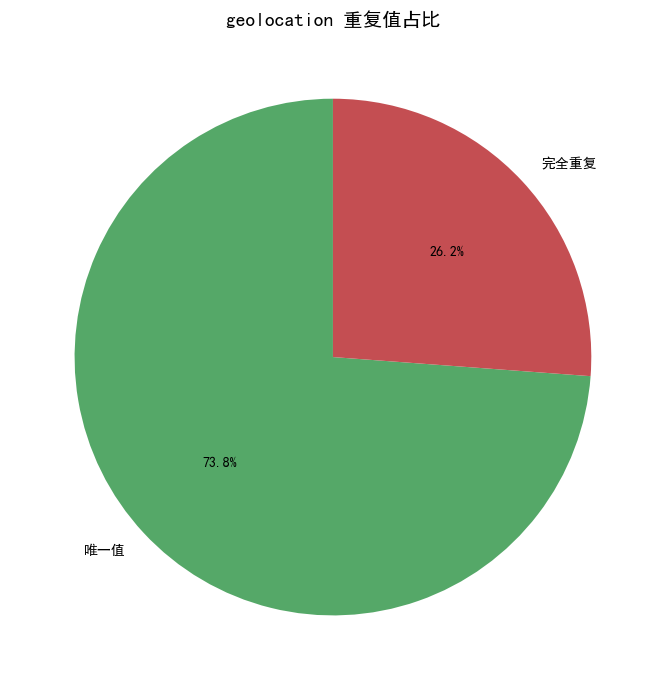

In [9]:
# 可视化：geolocation 重复占比饼图
fig, ax = plt.subplots(figsize=(7, 7))
uniq = df_dup.iloc[0]["distinct_rows"]
dup = df_dup.iloc[0]["dup_rows"]
ax.pie([uniq, dup], labels=["唯一值", "完全重复"],
       autopct="%1.1f%%", startangle=90,
       colors=["#55A868", "#C44E52"])
ax.set_title("geolocation 重复值占比", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


## 4. 主键唯一性检测

In [10]:
pk_sql = """
SELECT 'orders.order_id' AS pk_field, COUNT(*) AS total, COUNT(DISTINCT order_id) AS distinct_cnt FROM orders
UNION ALL SELECT 'customers.customer_id', COUNT(*), COUNT(DISTINCT customer_id) FROM customers
UNION ALL SELECT 'products.product_id', COUNT(*), COUNT(DISTINCT product_id) FROM products
UNION ALL SELECT 'sellers.seller_id', COUNT(*), COUNT(DISTINCT seller_id) FROM sellers
UNION ALL SELECT 'reviews.review_id', COUNT(*), COUNT(DISTINCT review_id) FROM order_reviews
"""
df_pk = spark.sql(pk_sql).toPandas()
df_pk["is_unique"] = df_pk["total"] == df_pk["distinct_cnt"]
df_pk


,pk_field,total,distinct_cnt,is_unique
0,orders.order_id,99441,99441,True
1,customers.customer_id,99441,99441,True
2,products.product_id,32951,32951,True
3,sellers.seller_id,3095,3095,True
4,reviews.review_id,104162,102957,False


## 5. 核心字段分布检测

In [11]:
# 5.1 订单状态分布
df_status = spark.sql(
    "SELECT order_status, COUNT(*) AS cnt FROM orders GROUP BY order_status ORDER BY cnt DESC"
).toPandas()
df_status


,order_status,cnt
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


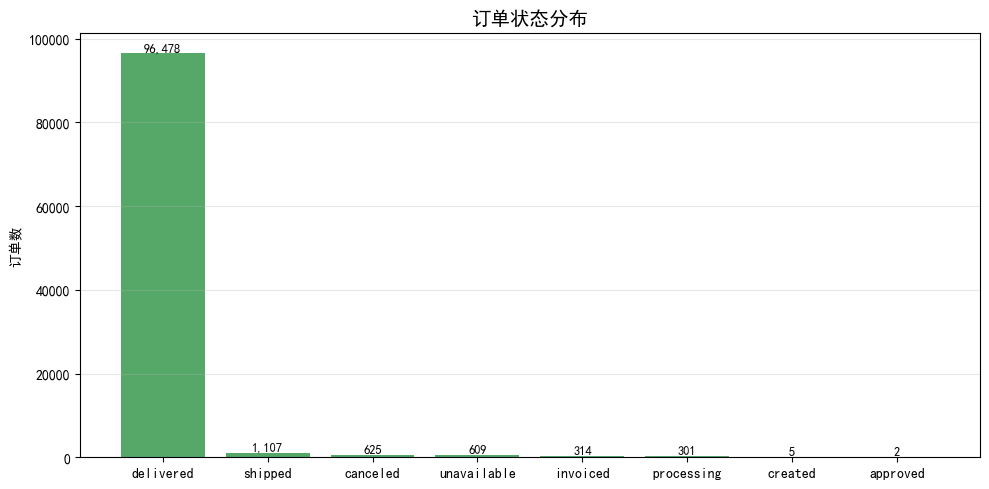

In [12]:
# 可视化：订单状态分布
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(df_status["order_status"], df_status["cnt"], color="#55A868")
for bar, v in zip(bars, df_status["cnt"]):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+500,
            f"{v:,}", ha="center", fontsize=9)
ax.set_title("订单状态分布", fontsize=14, fontweight="bold")
ax.set_ylabel("订单数")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [13]:
# 5.2 支付类型分布
df_pay = spark.sql(
    "SELECT payment_type, COUNT(*) AS cnt FROM order_payments GROUP BY payment_type ORDER BY cnt DESC"
).toPandas()
df_pay


,payment_type,cnt
0,credit_card,76795
1,boleto,19784
2,voucher,5775
3,debit_card,1529
4,not_defined,3


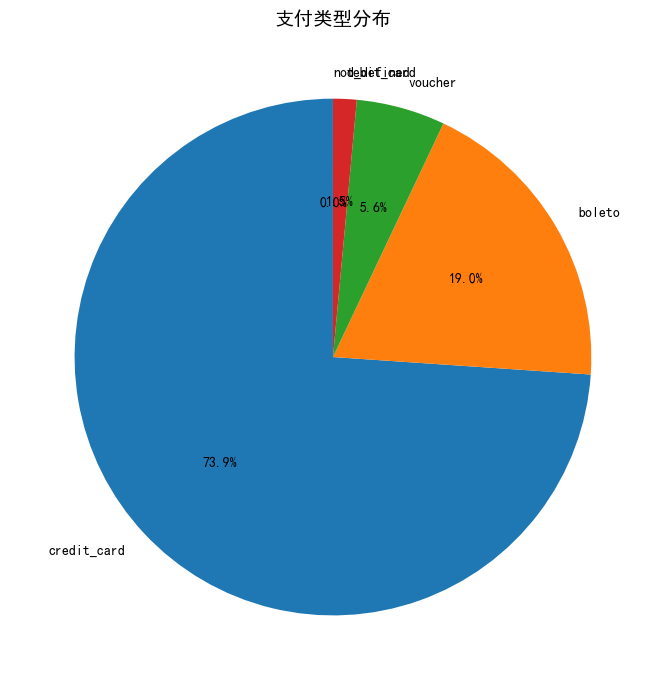

In [14]:
# 可视化：支付类型分布（饼图）
fig, ax = plt.subplots(figsize=(8, 7))
ax.pie(df_pay["cnt"], labels=df_pay["payment_type"], autopct="%1.1f%%", startangle=90)
ax.set_title("支付类型分布", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


In [15]:
# 5.3 评分分布
df_score = spark.sql(
    "SELECT review_score, COUNT(*) AS cnt FROM order_reviews GROUP BY review_score ORDER BY review_score"
).toPandas()
df_score


,review_score,cnt
0,None,2380
1,"""",1
2,BARALHO KEM COM NAIPES GRANDES E VEIRO COM NA...,1
3,"Desta vez nã""",1
4,M,1
...,...,...
2439,ficou muito bonita no quarto da minha filha,1
2440,nao tem no watsapp recebimento de videos e nem...,1
2441,pensei que era mais fosco,1
2442,rebi.mais com os numeros errados,1


/tmp/ipykernel_28716/1865363173.py:12: UserWarning: Glyph 199 (\N{LATIN CAPITAL LETTER C WITH CEDILLA}) missing from font(s) SimHei.
  plt.tight_layout()
/tmp/ipykernel_28716/1865363173.py:12: UserWarning: Glyph 218 (\N{LATIN CAPITAL LETTER U WITH ACUTE}) missing from font(s) SimHei.
  plt.tight_layout()
/tmp/ipykernel_28716/1865363173.py:12: UserWarning: Glyph 227 (\N{LATIN SMALL LETTER A WITH TILDE}) missing from font(s) SimHei.
  plt.tight_layout()
/tmp/ipykernel_28716/1865363173.py:12: UserWarning: Glyph 231 (\N{LATIN SMALL LETTER C WITH CEDILLA}) missing from font(s) SimHei.
  plt.tight_layout()
/tmp/ipykernel_28716/1865363173.py:12: UserWarning: Glyph 226 (\N{LATIN SMALL LETTER A WITH CIRCUMFLEX}) missing from font(s) SimHei.
  plt.tight_layout()
/tmp/ipykernel_28716/1865363173.py:12: UserWarning: Glyph 128079 (\N{CLAPPING HANDS SIGN}) missing from font(s) SimHei.
  plt.tight_layout()
/tmp/ipykernel_28716/1865363173.py:12: UserWarning: Glyph 128525 (\N{SMILING FACE WITH HEART-SHA

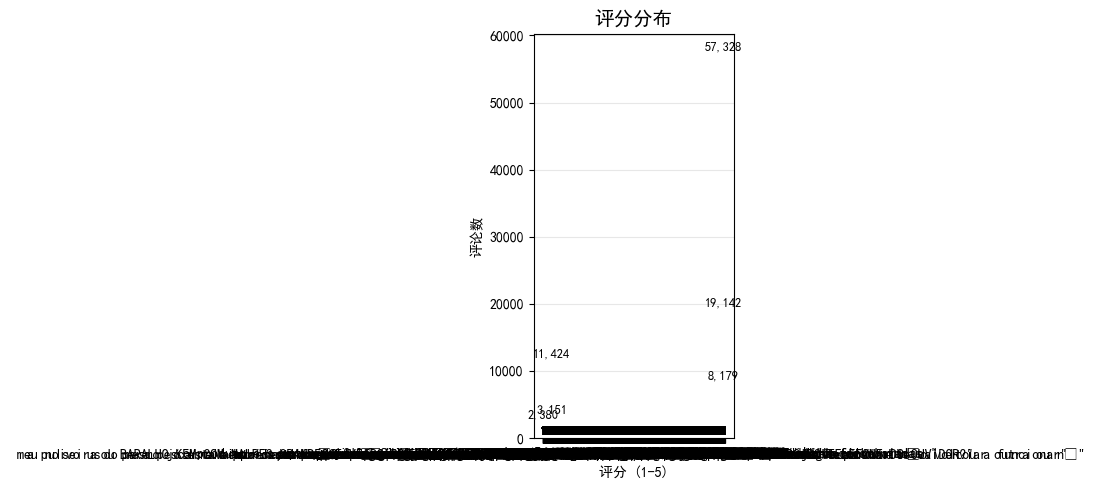

In [16]:
# 可视化：评分分布
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(df_score["review_score"].astype(str), df_score["cnt"],
              color=["#C44E52","#E08B6B","#CCB974","#9BBF77","#55A868"])
for bar, v in zip(bars, df_score["cnt"]):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+500,
            f"{v:,}", ha="center", fontsize=9)
ax.set_xlabel("评分 (1-5)")
ax.set_ylabel("评论数")
ax.set_title("评分分布", fontsize=14, fontweight="bold")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [17]:
# 5.4 价格统计（异常值检测）
price_sql = """
SELECT
    MIN(CAST(price AS DOUBLE)) AS min_price,
    MAX(CAST(price AS DOUBLE)) AS max_price,
    AVG(CAST(price AS DOUBLE)) AS avg_price,
    SUM(CASE WHEN CAST(price AS DOUBLE) <= 0 THEN 1 ELSE 0 END) AS non_positive_cnt,
    SUM(CASE WHEN CAST(freight_value AS DOUBLE) <= 0 THEN 1 ELSE 0 END) AS free_freight_cnt
FROM order_items
"""
df_price = spark.sql(price_sql).toPandas()
df_price


,min_price,max_price,avg_price,non_positive_cnt,free_freight_cnt
0,0.85,6735.0,120.653739,0,383


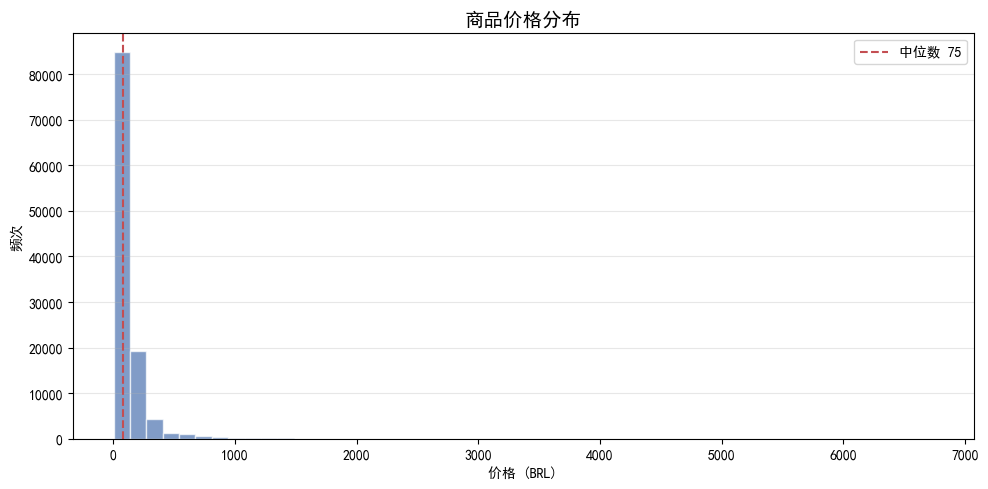

In [18]:
# 可视化：价格分布直方图
df_prices = spark.sql(
    "SELECT CAST(price AS DOUBLE) AS price FROM order_items WHERE CAST(price AS DOUBLE) > 0"
).toPandas()
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df_prices["price"], bins=50, color="#4C72B0", alpha=0.7, edgecolor="white")
ax.axvline(df_prices["price"].median(), color="#C44E52", linestyle="--",
           label=f"中位数 {df_prices['price'].median():.0f}")
ax.set_xlabel("价格 (BRL)")
ax.set_ylabel("频次")
ax.set_title("商品价格分布", fontsize=14, fontweight="bold")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [19]:
# 5.5 下单时间范围
df_time = spark.sql(
    "SELECT MIN(order_purchase_timestamp) AS min_time, MAX(order_purchase_timestamp) AS max_time FROM orders"
).toPandas()
df_time


,min_time,max_time
0,2016-09-04 21:15:19,2018-10-17 17:30:18


## 6. 质量检测结论汇总

In [20]:
print("=" * 60)
print("Olist 数据质量检测结论（PySpark 直读 HDFS）")
print("=" * 60)

geo_cnt = df_cnt[df_cnt["table_name"]=="geolocation"]["row_cnt"].iloc[0]
print(f"\n[数据量] 共 {len(df_cnt)} 张表，最大表 geolocation {geo_cnt:,} 行")

max_missing = df_missing.loc[df_missing["missing_rate"].idxmax()]
print(f"\n[缺失] 最高缺失率字段: {max_missing['field']} ({max_missing['missing_rate']}%)，属评论文本选填，正常")

print(f"\n[重复] geolocation 完全重复 {df_dup.iloc[0]['dup_rows']:,} 行 ({df_dup.iloc[0]['dup_rate']}%)，需去重")

all_unique = df_pk["is_unique"].all()
print(f"\n[主键] 所有主键唯一性: {'通过' if all_unique else '存在重复，需检查'}")

print(f"\n[异常] 价格为非正数 {df_price.iloc[0]['non_positive_cnt']} 行；免运费 {df_price.iloc[0]['free_freight_cnt']} 行")

print(f"\n[时间] 下单时间范围: {df_time.iloc[0]['min_time']} ~ {df_time.iloc[0]['max_time']}")

print("\n" + "=" * 60)
print("总体评价：数据质量良好，可直接进入清洗阶段")
print("清洗重点：1) geolocation 去重 2) 类型转换 3) 缺失类目补 unknown")
print("=" * 60)

# 释放 Spark 资源
spark.stop()


Olist 数据质量检测结论（PySpark 直读 HDFS）

[数据量] 共 9 张表，最大表 geolocation 1,000,163 行

[缺失] 最高缺失率字段: reviews.review_comment_title (88.47%)，属评论文本选填，正常

[重复] geolocation 完全重复 261,831.0 行 (26.18%)，需去重

[主键] 所有主键唯一性: 存在重复，需检查

[异常] 价格为非正数 0.0 行；免运费 383.0 行

[时间] 下单时间范围: 2016-09-04 21:15:19 ~ 2018-10-17 17:30:18

总体评价：数据质量良好，可直接进入清洗阶段
清洗重点：1) geolocation 去重 2) 类型转换 3) 缺失类目补 unknown
